# PDSI — Parte 2 | Segmentação de regiões com IA (SAM)

**Pessoa 2:** segmentar o **manto** (principal), o **rosto** e o **vestido** da imagem de Nossa Senhora de Guadalupe com o modelo pré-treinado **SAM** (Segment Anything, Meta), guiado por pontos.

**Entrada:** `img_011.jpeg` (1200 × 1800, RGB).
**Saídas:** `mascara_manto.png`, `mascara_rosto.png`, `mascara_vestido.png` (1 canal, valores 0/255, mesmo tamanho da imagem), `mapa_regioes.png` (0 = fundo, 1 = manto, 2 = rosto, 3 = vestido), `parametros_segmentacao.json` e figuras de sobreposição.

**Como cada região é feita:**
1. Pontos positivos (está na região) e negativos (não está) → o SAM devolve 3 máscaras candidatas.
2. Escolhemos a melhor e **refinamos** com o próprio SAM (a máscara escolhida volta como entrada junto com os pontos).
3. **Limpeza:** fechamento morfológico (furos das estrelas), abertura opcional (corta "espinhas" finas), remoção de ilhas soltas e preenchimento só de buracos pequenos.
4. Verificação visual com zoom nas bordas.

> Limitação: o resultado depende dos pontos escolhidos e o *score* do SAM é uma autoavaliação do modelo, não uma medida de acerto. Não há máscara de referência para calcular IoU.

**Rode as células em ordem.** Se o Colab ficar parado e "esquecer" as variáveis, use *Ambiente de execução → Executar tudo*.

## 1. Configuração (GPU, SAM e modelo)
Ative a GPU em *Ambiente de execução → Alterar tipo → T4 GPU*.

In [23]:
!nvidia-smi -L
!pip install -q git+https://github.com/facebookresearch/segment-anything.git
# O certificado do servidor da Meta está com problema no Colab; baixamos sem checar
# e conferimos a integridade pelo MD5 logo abaixo.
!wget -nc -q --no-check-certificate https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth

import hashlib, os
CKPT = 'sam_vit_b_01ec64.pth'
md5 = hashlib.md5(open(CKPT, 'rb').read()).hexdigest()
print(f'{CKPT}: {os.path.getsize(CKPT)/1024**2:.0f} MB | MD5 {md5}')
print('Integridade OK' if md5.startswith('01ec64') else 'ATENÇÃO: MD5 não confere, baixe de novo')

GPU 0: Tesla T4 (UUID: GPU-c2d5778a-e4af-bba6-f6f9-6b08a36d2c9e)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
sam_vit_b_01ec64.pth: 358 MB | MD5 01ec64d29a2fca3f0661936605ae66f8
Integridade OK


## 2. Carregar o modelo

In [24]:
import json
import torch, cv2, numpy as np, matplotlib.pyplot as plt
from segment_anything import sam_model_registry, SamPredictor

device = 'cuda' if torch.cuda.is_available() else 'cpu'
sam = sam_model_registry['vit_b'](checkpoint=CKPT).to(device)
predictor = SamPredictor(sam)
print('Modelo carregado em', device)

Modelo carregado em cuda


## 3. Carregar a imagem
Envie a `img_011.jpeg`. A grade de 100 em 100 px serve para ler as coordenadas (x, y) dos pontos.

Saving img_011.jpeg to img_011 (1).jpeg
Imagem: img_011 (1).jpeg | shape: (1800, 1200, 3)


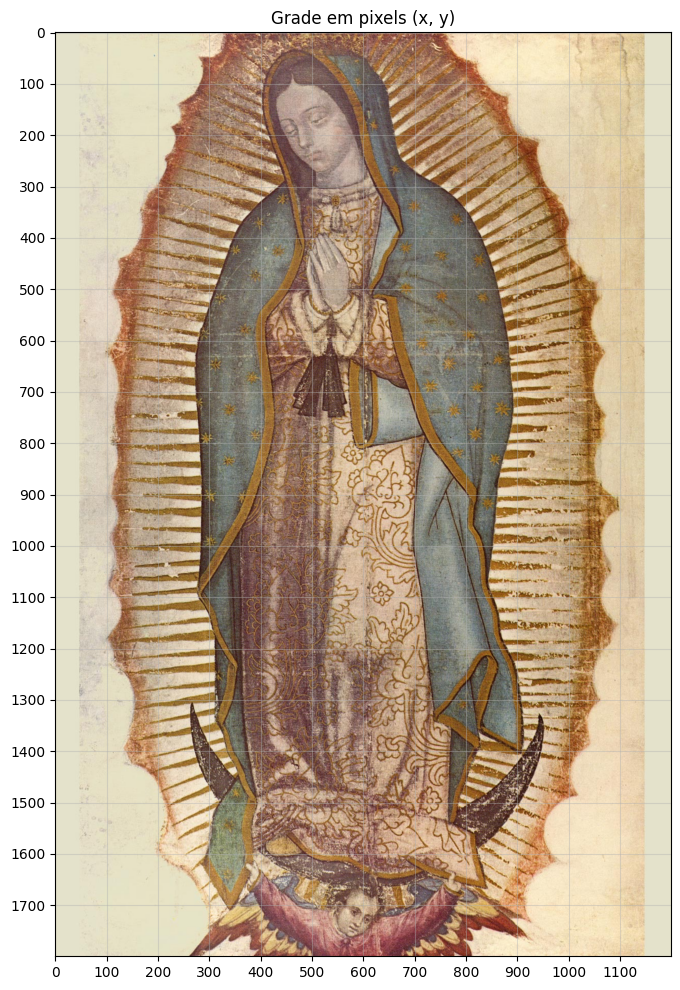

Imagem preparada no SAM


In [25]:
from google.colab import files
nome = next(iter(files.upload()))
img = cv2.cvtColor(cv2.imread(nome), cv2.COLOR_BGR2RGB)
H, W = img.shape[:2]
print('Imagem:', nome, '| shape:', img.shape)

plt.figure(figsize=(8, 12)); plt.imshow(img)
plt.xticks(range(0, W, 100)); plt.yticks(range(0, H, 100)); plt.grid(alpha=0.4)
plt.title('Grade em pixels (x, y)'); plt.show()

predictor.set_image(img)   # o SAM "estuda" a imagem uma vez; vale para todas as regiões
print('Imagem preparada no SAM')

## 4. Funções reutilizáveis
- `testar(nome, pos, neg)`: roda o SAM e mostra as 3 candidatas.
- `finalizar(nome, escolha, ...)`: refina, limpa, verifica e guarda a máscara da região.

In [26]:
CAND, REGIOES = {}, {}

def _desenhar(ax, base, mask, pts=None, lbl=None):
    ax.imshow(base)
    ax.imshow(np.ma.masked_where(mask == 0, mask), alpha=0.55, cmap='cool', vmin=0, vmax=1)
    if pts is not None:
        ax.plot(pts[lbl == 1, 0], pts[lbl == 1, 1], 'g*', markersize=16)
        ax.plot(pts[lbl == 0, 0], pts[lbl == 0, 1], 'rx', markersize=12, mew=3)
    ax.axis('off')

def testar(nome, pos, neg):
    pts = np.array(pos + neg)
    lbl = np.array([1] * len(pos) + [0] * len(neg))
    masks, scores, logits = predictor.predict(point_coords=pts, point_labels=lbl, multimask_output=True)
    CAND[nome] = dict(pos=pos, neg=neg, pts=pts, lbl=lbl, masks=masks, scores=scores, logits=logits)
    fig, axs = plt.subplots(1, 3, figsize=(15, 8))
    for i, (ax, m, s) in enumerate(zip(axs, masks, scores)):
        print(f'{nome} | máscara {i}: score {s:.3f} | {m.mean()*100:.1f}% da imagem')
        _desenhar(ax, img, m.astype(np.uint8), pts, lbl)
        ax.set_title(f'{nome} | máscara {i} | score {s:.3f}')
    plt.tight_layout(); plt.show()

def limpar(mask, k_fechar=15, k_abrir=0, area_min=0.005, buraco_max=0.003):
    # mask: bool/0-1 -> devolve uint8 0/255
    m = mask.astype(np.uint8) * 255
    h, w = m.shape
    elipse = lambda k: cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
    if k_fechar: m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, elipse(k_fechar))   # fecha furos pequenos (estrelas)
    if k_abrir:  m = cv2.morphologyEx(m, cv2.MORPH_OPEN, elipse(k_abrir))     # corta espinhas finas
    # remove ilhas soltas pequenas
    n, rot, st, _ = cv2.connectedComponentsWithStats(m)
    m = np.isin(rot, [i for i in range(1, n) if st[i, cv2.CC_STAT_AREA] >= area_min * h * w]).astype(np.uint8) * 255
    # preenche só buracos pequenos (não engole, por exemplo, as mãos dentro do vestido)
    n, rot, st, _ = cv2.connectedComponentsWithStats(255 - m)
    for i in range(1, n):
        x, y, bw, bh, a = st[i]
        toca_borda = x == 0 or y == 0 or x + bw == w or y + bh == h
        if not toca_borda and a < buraco_max * h * w:
            m[rot == i] = 255
    return m

def finalizar(nome, escolha, refinar=True, k_fechar=15, k_abrir=0, area_min=0.005, buraco_max=0.003, zooms=()):
    c = CAND[nome]
    bruta, score = c['masks'][escolha], float(c['scores'][escolha])
    if refinar:   # devolve a máscara escolhida ao SAM junto com os pontos
        m, s, _ = predictor.predict(point_coords=c['pts'], point_labels=c['lbl'],
                                    mask_input=c['logits'][escolha][None, :, :], multimask_output=False)
        print(f'Refinamento: {bruta.mean()*100:.1f}% -> {m[0].mean()*100:.1f}% da imagem | score {score:.3f} -> {float(s[0]):.3f}')
        bruta, score = m[0], float(s[0])
    limpa = limpar(bruta, k_fechar, k_abrir, area_min, buraco_max)

    assert limpa.shape == (H, W), 'Máscara com tamanho diferente da imagem!'
    assert set(np.unique(limpa)) <= {0, 255}
    print(f'{nome}: antes da limpeza {bruta.mean()*100:.1f}% | depois {(limpa > 0).mean()*100:.1f}% da imagem')

    fig, axs = plt.subplots(1, 3, figsize=(15, 8))
    axs[0].imshow(img); axs[0].set_title('Original'); axs[0].axis('off')
    axs[1].imshow(limpa, cmap='gray'); axs[1].set_title(f'Máscara: {nome}'); axs[1].axis('off')
    _desenhar(axs[2], img, limpa // 255); axs[2].set_title('Sobreposição')
    plt.tight_layout(); plt.savefig(f'sobreposicao_{nome}.png', dpi=150, bbox_inches='tight'); plt.show()

    if zooms:   # inspeção das bordas: (x0, y0, x1, y1)
        fig, axs = plt.subplots(1, len(zooms), figsize=(6 * len(zooms), 6))
        for ax, (x0, y0, x1, y1) in zip(np.atleast_1d(axs), zooms):
            _desenhar(ax, img[y0:y1, x0:x1], limpa[y0:y1, x0:x1] // 255)
            ax.set_title(f'zoom x {x0}-{x1}, y {y0}-{y1}')
        plt.tight_layout(); plt.show()

    REGIOES[nome] = dict(mascara=limpa, params=dict(
        pontos_positivos=c['pos'], pontos_negativos=c['neg'], mascara_escolhida=escolha,
        refinado=refinar, score=round(score, 4), k_fechar=k_fechar, k_abrir=k_abrir,
        area_min=area_min, buraco_max=buraco_max))
    print(f'Região "{nome}" guardada.')

## 5. Manto (região principal)
Pontos conferidos sobre a imagem. Em relação à versão anterior: 2 negativos novos (gola, perto do pescoço, e raio à esquerda) e **abertura** (`k_abrir`) para cortar a "espinha" fina que encosta no manto.

manto | máscara 0: score 0.822 | 29.6% da imagem
manto | máscara 1: score 0.849 | 18.9% da imagem
manto | máscara 2: score 0.797 | 15.8% da imagem


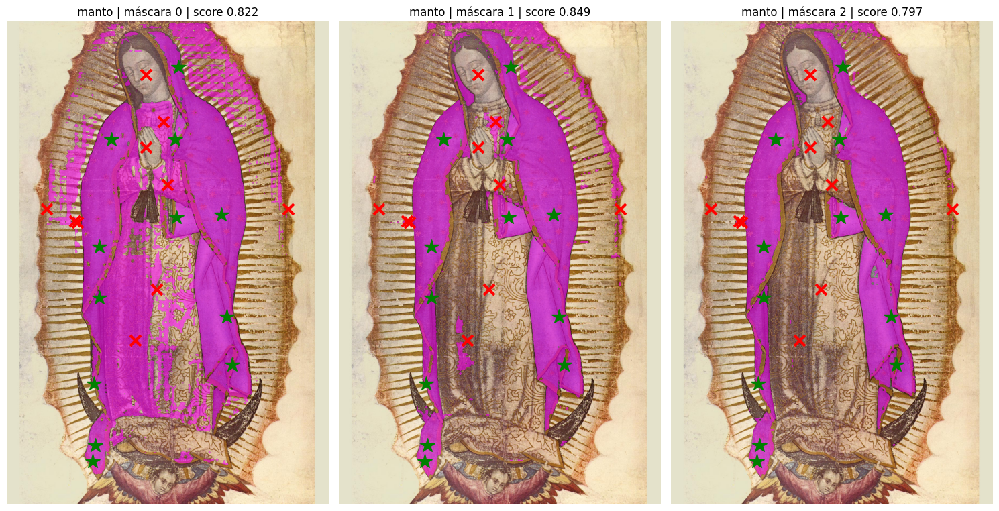

In [27]:
manto_pos = [[345, 840], [800, 720], [640, 170], [390, 440], [345, 1030], [820, 1100], [330, 1580], [840, 1280],
             [325, 1350], [320, 1640],
             [628, 440], [632, 730]]                                            # novos: forro azul-claro perto da mão
manto_neg = [[520, 200], [520, 470], [560, 1000], [150, 700], [1050, 700],
             [255, 745], [600, 610], [480, 1190], [585, 375], [265, 750]]
testar('manto', manto_pos, manto_neg)

Refinamento: 18.9% -> 15.6% da imagem | score 0.849 -> 0.878
manto: antes da limpeza 15.6% | depois 15.2% da imagem


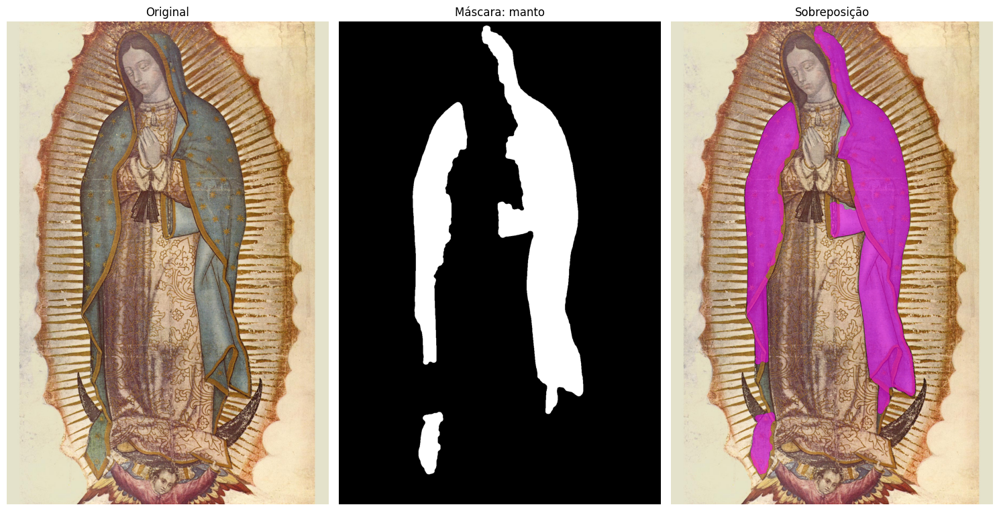

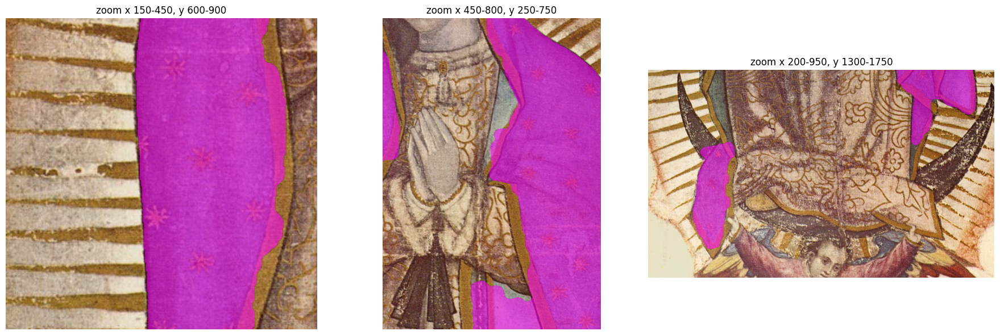

Região "manto" guardada.


In [28]:
finalizar('manto', escolha=1, refinar=True, k_fechar=15, k_abrir=21, area_min=0.005,
          zooms=[(150, 600, 450, 900), (450, 250, 800, 750), (200, 1300, 950, 1750)])
# Se a espinha à esquerda continuar: k_abrir=27. Se o manto perder pedaços finos: k_abrir=15.
# Se o refinamento piorar: refinar=False.

## 6. Rosto (opcional)
Positivos na pele do rosto; negativos no cabelo, no manto, na gola e nas mãos.

rosto | máscara 0: score 0.616 | 0.3% da imagem
rosto | máscara 1: score 0.760 | 1.4% da imagem
rosto | máscara 2: score 0.979 | 1.1% da imagem


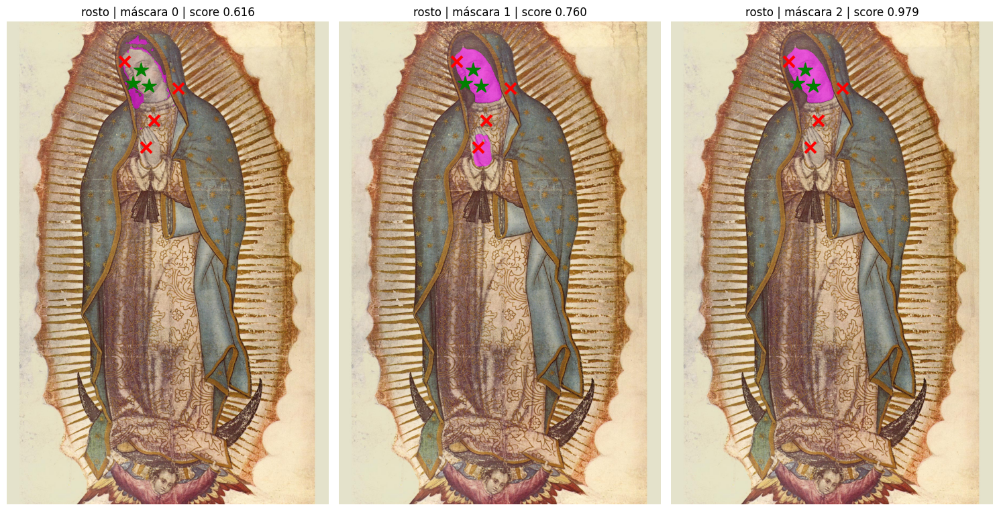

In [29]:
rosto_pos = [[500, 180], [530, 240], [470, 230]]
rosto_neg = [[440, 150], [640, 250], [550, 370], [520, 470]]   # cabelo, manto, gola, mãos
testar('rosto', rosto_pos, rosto_neg)

Refinamento: 1.4% -> 1.1% da imagem | score 0.760 -> 0.967
rosto: antes da limpeza 1.1% | depois 1.1% da imagem


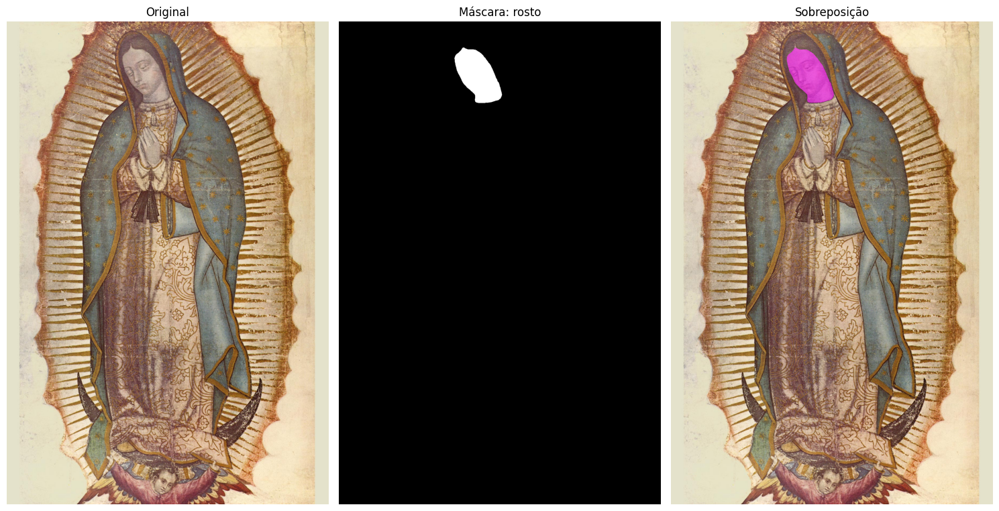

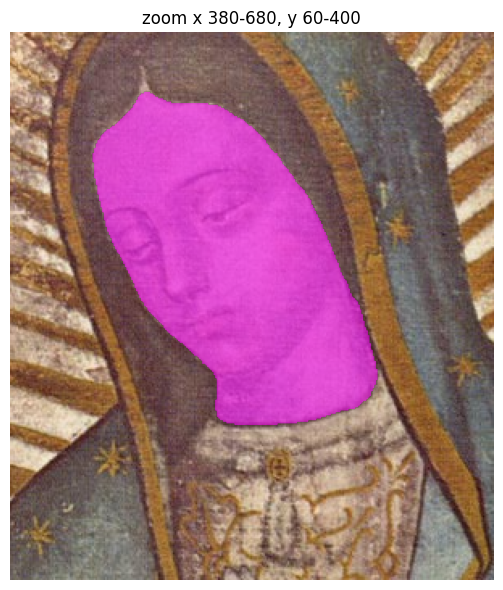

Região "rosto" guardada.


In [30]:
finalizar('rosto', escolha=1, refinar=True, k_fechar=7, k_abrir=0, area_min=0.002,
          zooms=[(380, 60, 680, 400)])

## 7. Vestido (opcional)
Positivos no vestido rosado/dourado (incluindo os punhos e a barra); negativos no manto, no forro azul, nas mãos, no rosto, na lua e no anjo.

vestido | máscara 0: score 0.835 | 30.7% da imagem
vestido | máscara 1: score 0.808 | 22.2% da imagem
vestido | máscara 2: score 0.691 | 14.9% da imagem


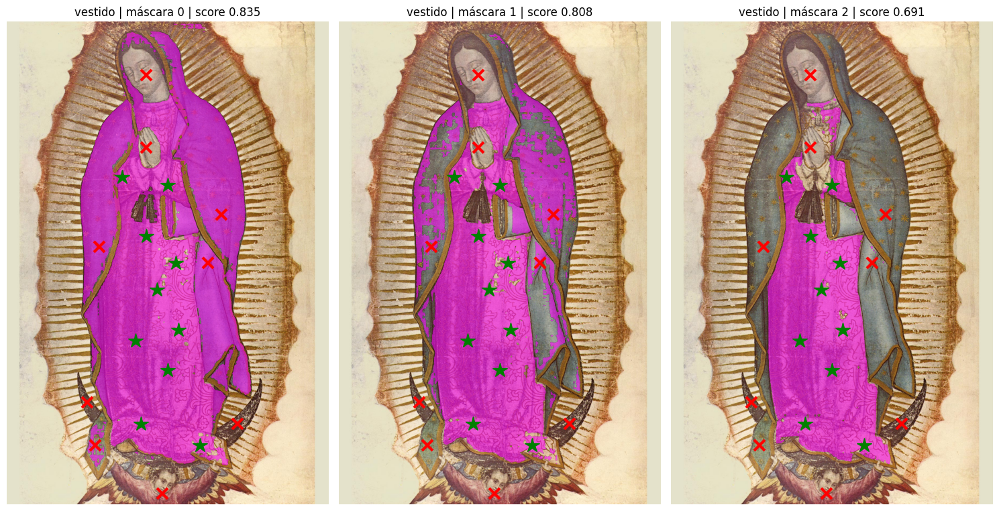

In [31]:
vestido_pos = [[560, 1000], [480, 1190], [600, 610], [520, 800], [600, 1300], [430, 580], [500, 1500],
               [630, 900], [640, 1150], [720, 1580]]                            # novos: faixa clara + dobra da barra
vestido_neg = [[345, 840], [800, 720], [750, 900], [520, 470], [520, 200],      # [690,800] trocado por [750,900] (forro azul)
               [300, 1420], [860, 1500], [580, 1760], [330, 1580]]              # novo: ponta do manto embaixo
testar('vestido', vestido_pos, vestido_neg)

Refinamento: 22.2% -> 16.2% da imagem | score 0.808 -> 0.958
vestido: antes da limpeza 16.2% | depois 16.3% da imagem


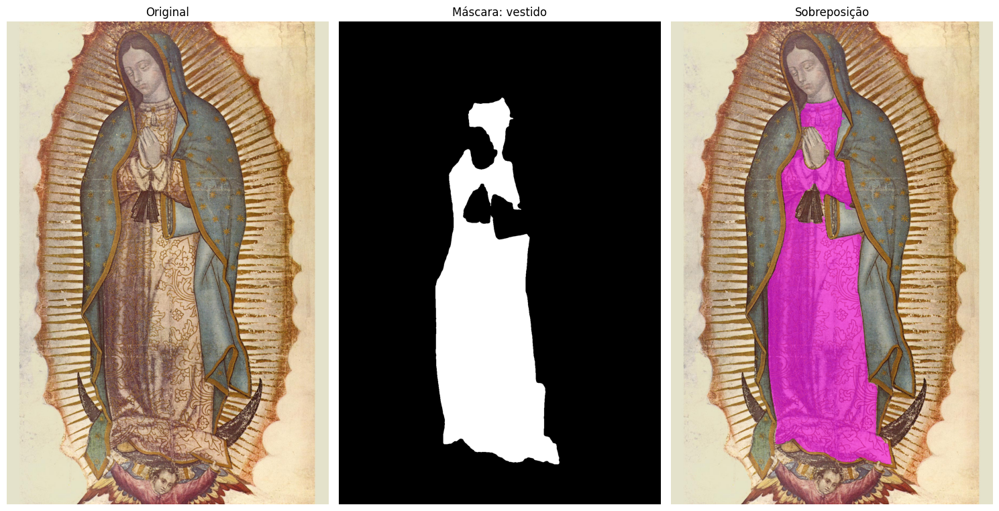

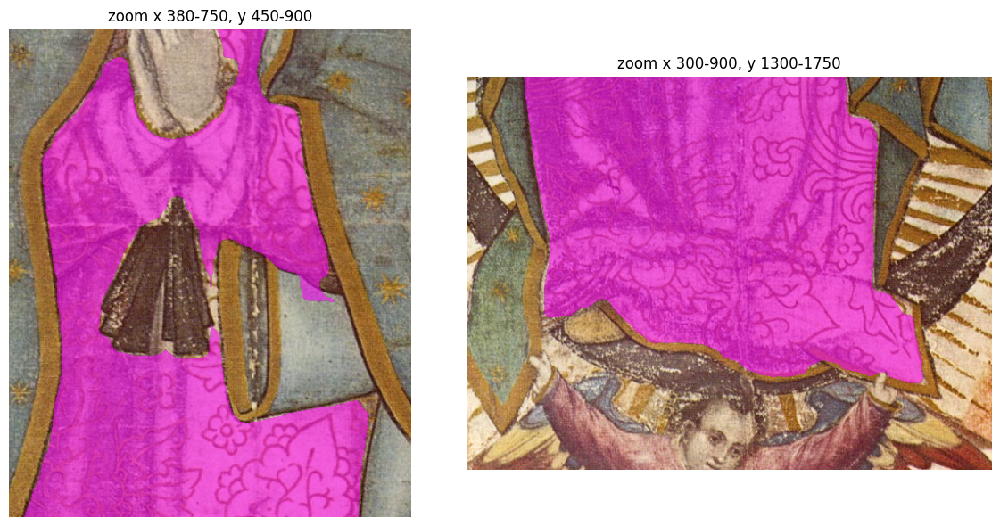

Região "vestido" guardada.


In [32]:
finalizar('vestido', escolha=1, refinar=True, k_fechar=15, k_abrir=0, area_min=0.005,
          zooms=[(380, 450, 750, 900), (300, 1300, 900, 1750)])

## 8. Juntar as regiões e exportar
Cada pixel pode pertencer a uma região só. Prioridade nas sobreposições: **rosto > manto > vestido** (o manto é o foco do projeto; a borda dourada entre manto e vestido fica com o manto).

vestido: 175 px já pertenciam a outra região e foram mantidos nela
mascara_manto.png: 15.2% da imagem
mascara_rosto.png: 1.1% da imagem
mascara_vestido.png: 16.3% da imagem


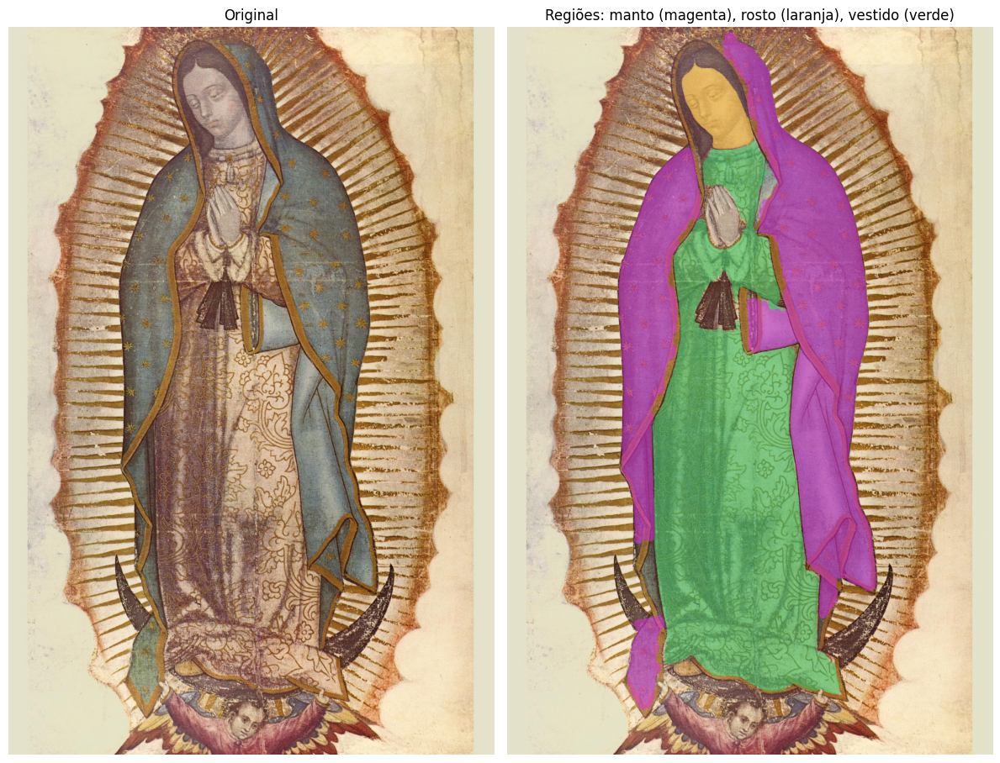

Arquivos: ['mascara_manto.png', 'sobreposicao_manto.png', 'mascara_rosto.png', 'sobreposicao_rosto.png', 'mascara_vestido.png', 'sobreposicao_vestido.png', 'mapa_regioes.png', 'parametros_segmentacao.json', 'regioes_sobreposicao.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [33]:
import zipfile
ordem = [n for n in ['rosto', 'manto', 'vestido'] if n in REGIOES]   # prioridade
codigo = {'manto': 1, 'rosto': 2, 'vestido': 3}
mapa = np.zeros((H, W), np.uint8)
for n in ordem:
    m = REGIOES[n]['mascara'] > 0
    conflito = (m & (mapa > 0)).sum()
    if conflito: print(f'{n}: {conflito} px já pertenciam a outra região e foram mantidos nela')
    mapa[m & (mapa == 0)] = codigo[n]

arquivos = []
for n in REGIOES:
    final = np.where(mapa == codigo[n], 255, 0).astype(np.uint8)
    assert final.shape == (H, W)
    cv2.imwrite(f'mascara_{n}.png', final); arquivos += [f'mascara_{n}.png', f'sobreposicao_{n}.png']
    print(f'mascara_{n}.png: {(final > 0).mean()*100:.1f}% da imagem')
cv2.imwrite('mapa_regioes.png', mapa); arquivos.append('mapa_regioes.png')

json.dump({'imagem': nome, 'shape': [H, W, 3], 'modelo': 'SAM vit_b (sam_vit_b_01ec64.pth)',
           'codigos_mapa': {'fundo': 0, **{n: codigo[n] for n in REGIOES}}, 'prioridade': ordem,
           'regioes': {n: REGIOES[n]['params'] for n in REGIOES}},
          open('parametros_segmentacao.json', 'w'), indent=2, ensure_ascii=False)
arquivos.append('parametros_segmentacao.json')

# Figura para os slides
cores = {1: (0.85, 0.2, 0.85), 2: (1.0, 0.75, 0.2), 3: (0.2, 0.8, 0.4)}
sobre = img.astype(float) / 255
for k, cor in cores.items():
    sobre[mapa == k] = 0.45 * sobre[mapa == k] + 0.55 * np.array(cor)
fig, axs = plt.subplots(1, 2, figsize=(12, 9))
axs[0].imshow(img); axs[0].set_title('Original')
axs[1].imshow(sobre); axs[1].set_title('Regiões: manto (magenta), rosto (laranja), vestido (verde)')
for ax in axs: ax.axis('off')
plt.tight_layout(); plt.savefig('regioes_sobreposicao.png', dpi=150, bbox_inches='tight'); plt.show()
arquivos.append('regioes_sobreposicao.png')

with zipfile.ZipFile('pdsi_parte2_segmentacao.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    for a in arquivos: z.write(a)
print('Arquivos:', arquivos)
files.download('pdsi_parte2_segmentacao.zip')

## 9. Como a Pessoa 3 usa as máscaras
```python
mascara = cv2.imread('mascara_manto.png', cv2.IMREAD_GRAYSCALE)
assert mascara.shape == img.shape[:2]
pixels_manto = img[mascara > 0]          # array (N, 3) só com os pixels do manto
# ou, com o mapa: img[mapa == 1] -> manto, img[mapa == 2] -> rosto, img[mapa == 3] -> vestido
```